In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import os
import json
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import gpflow
import tensorflow as tf

2026-01-21 13:31:53.877222: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-21 13:31:53.891135: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769027513.902490   66421 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769027513.906831   66421 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-01-21 13:31:53.925060: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
from utils.pyfunctions import *
from utils.hm_pyfunctions import *
utils_path = '../utils/'

In [3]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
u_params = param_info['u_params']
pft_params = param_info['pft_params']

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

### Biome emulators

In [4]:
### Load data
ds_params_lhc = xr.open_dataset('./paramsets/clm6lhc_01192025_v3.nc')
ds_lhc = xr.open_dataset('../data/ctsm53065_lhc_biome_1850-2023.nc')

In [5]:
### Load wave1 data
ds_params_wave1 = xr.open_dataset('./paramsets/ctsm53065_wave1_12032025.nc')
ds_wave1 = xr.open_dataset('../data/ctsm53065_wave1_biome_1850-2023.nc')

In [6]:
### Load wave2 data
ds_params_wave2 = xr.open_dataset('./paramsets/ctsm53065_wave2_12232025.nc')
ds_wave2 = xr.open_dataset('../data/ctsm53065_wave2_biome_1850-2023.nc')

In [7]:
### Load wave3 data
ds_params_wave3 = xr.open_dataset('./paramsets/ctsm53065_wave3_01012026.nc')
ds_wave3 = xr.open_dataset('../data/ctsm53065_wave3_biome_1850-2023.nc')

In [8]:
# concat
ds_X = xr.concat([ds_params_lhc.lhc_params, ds_params_wave1.wave1_params, ds_params_wave2.wave2_params, ds_params_wave3.wave3_params], dim="ens")
ds_X = ds_X.assign_coords(ens=range(0, len(ds_X.ens)))
ds_Y = xr.concat([ds_lhc.sel(ens=slice(1,201)),ds_wave1,ds_wave2,ds_wave3],dim='ens') # drop default lhc0000

In [9]:
# train test split (same for all emulators)
np.random.seed(20)
ntest = 80
biome_pfts = biome_info['13']['pfts_in_biome']
X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
ix_test = np.random.choice(np.arange(len(X)), size=ntest, replace=False)
ix_train = np.where(~np.isin(np.arange(len(X)), ix_test))[0]

INFO:tensorflow:Assets written to: ./emulators/biome_lai_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_lai_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_13/assets


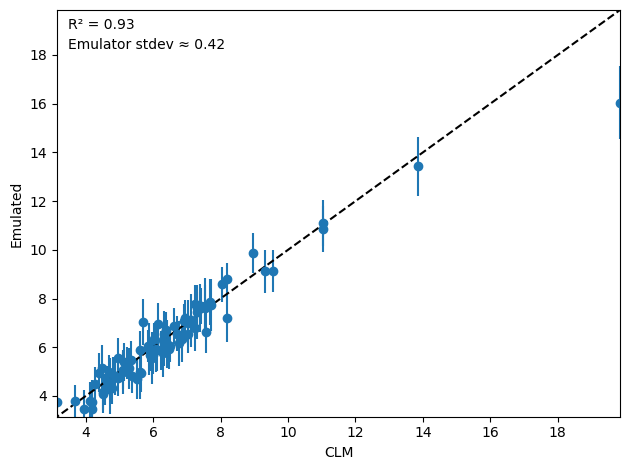

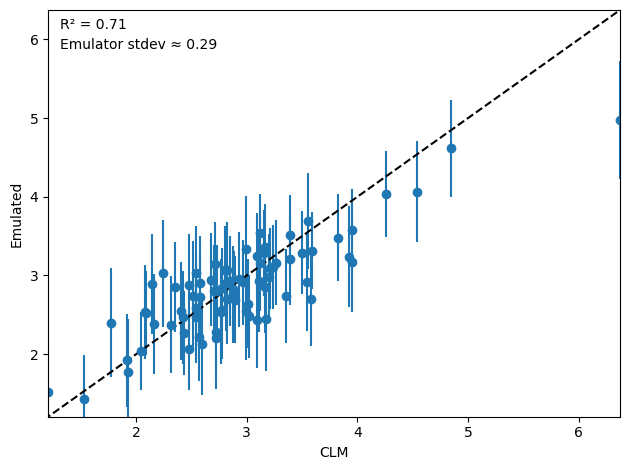

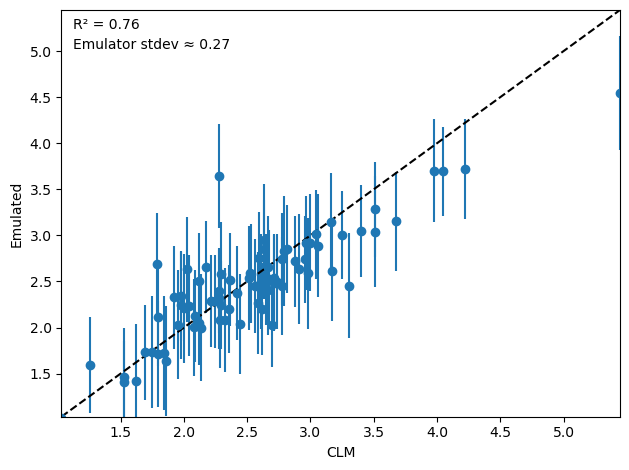

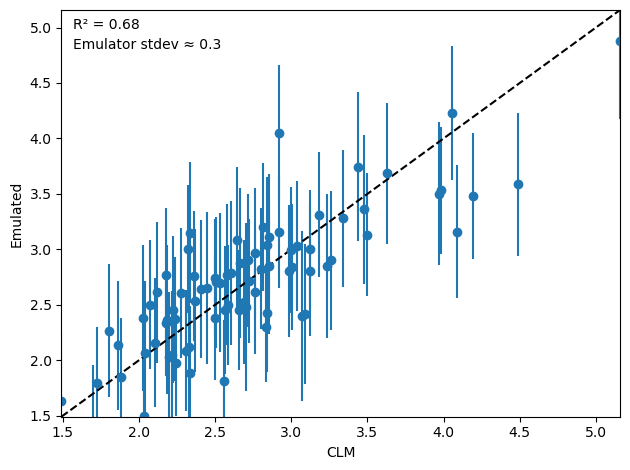

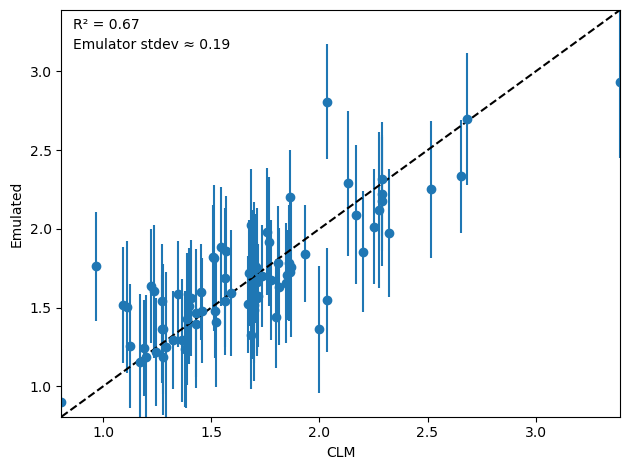

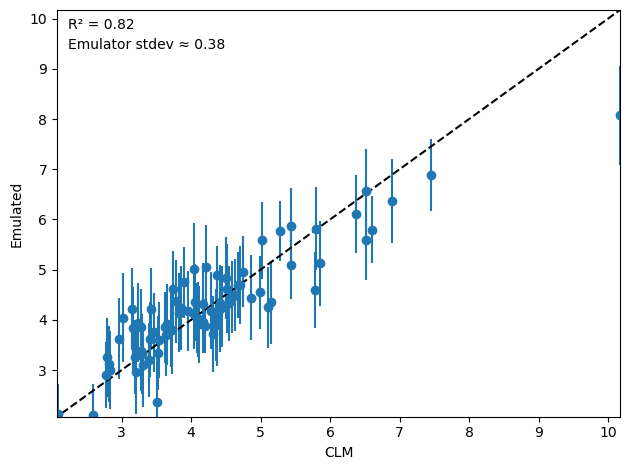

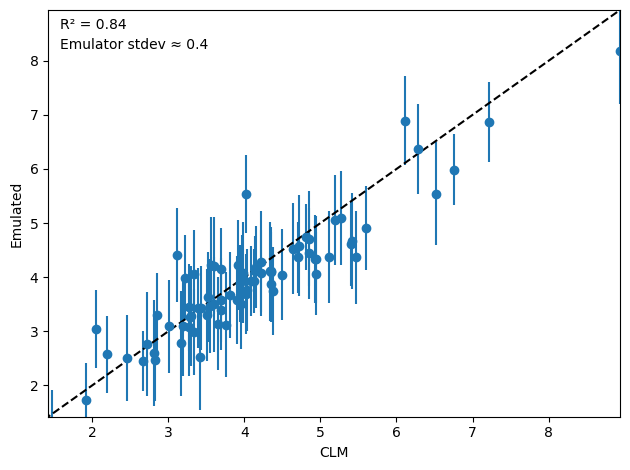

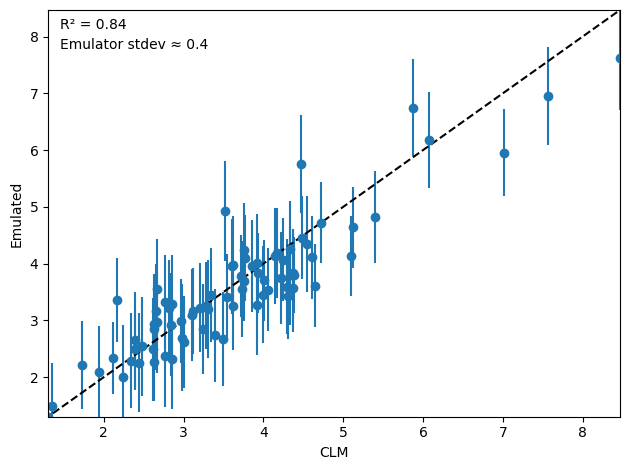

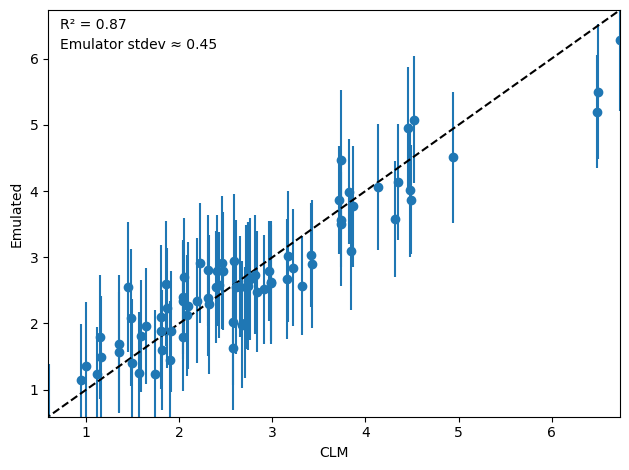

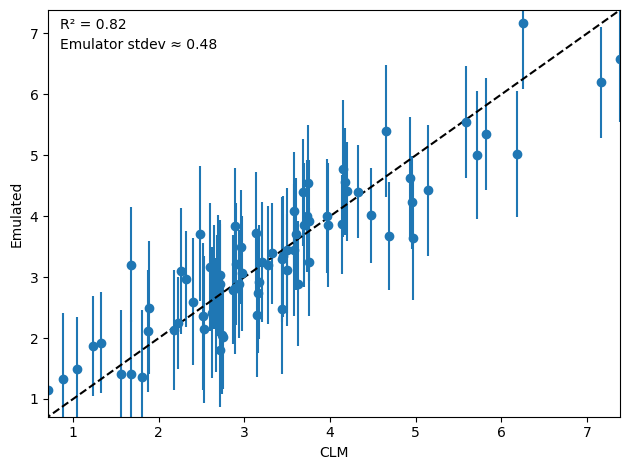

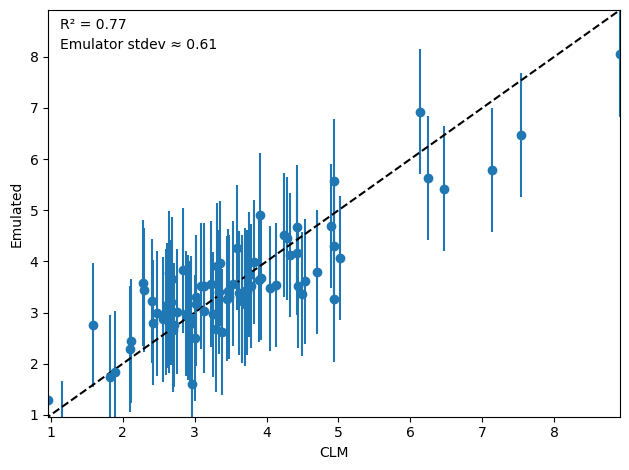

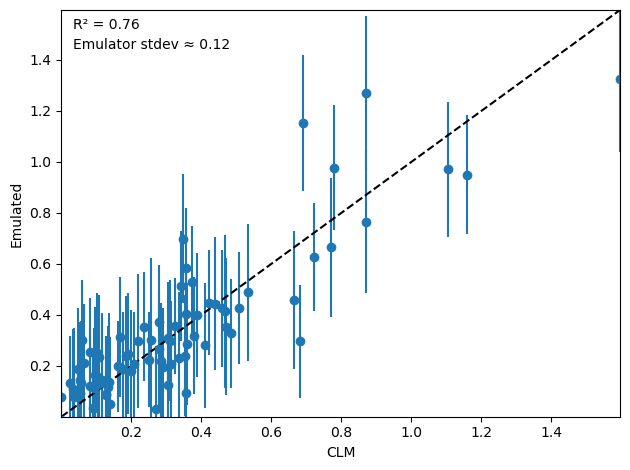

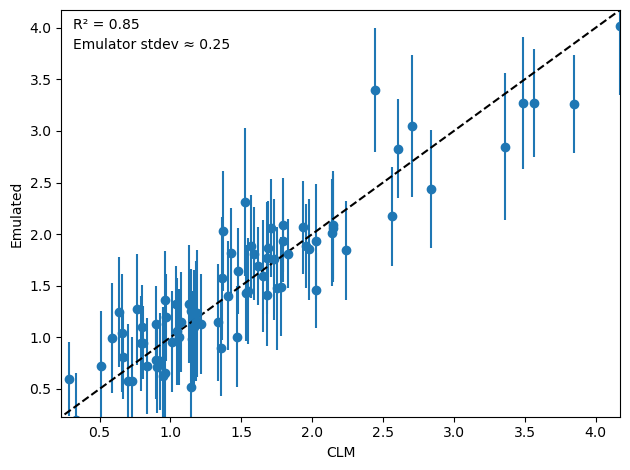

In [47]:
# Train LAI emulators (2001-2020)
start_year = '2001'
end_year = '2020'
y_data = ds_Y.TLAI_biome_amax.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './wave4_emulators/biome_lai_'
validation_fig_dir = './figs/emulator_validation_laimax_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_gpp_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_13/assets


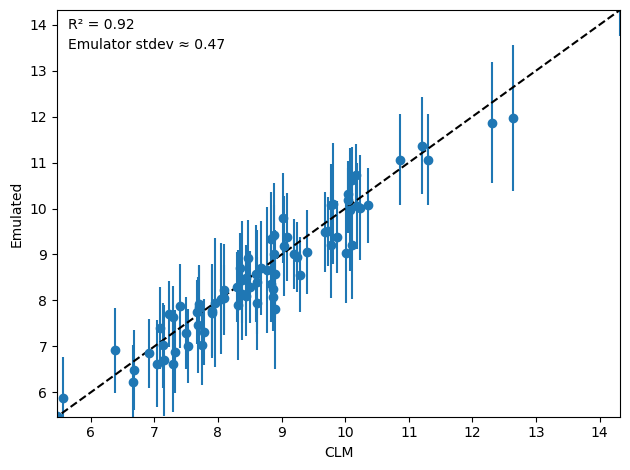

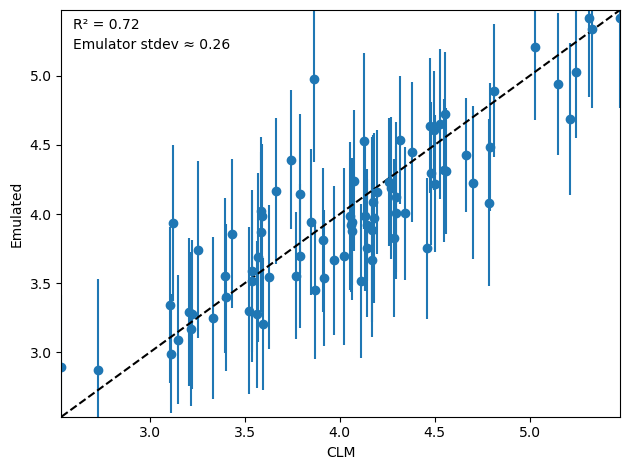

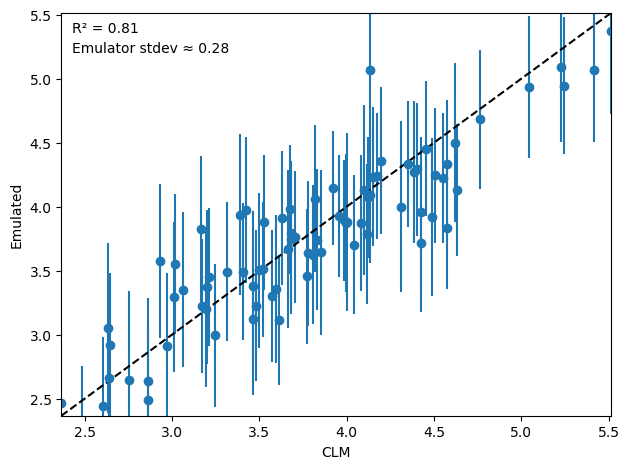

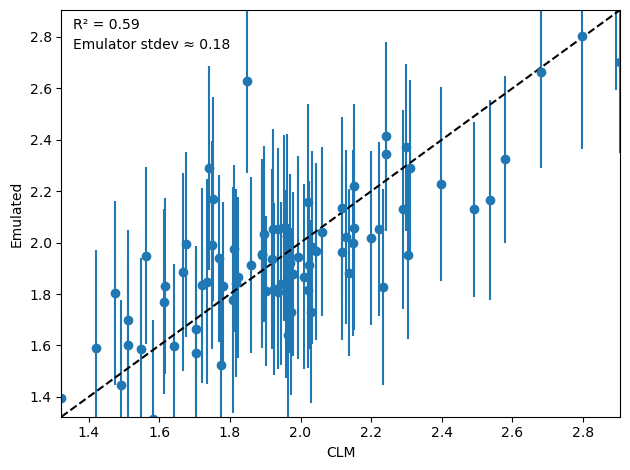

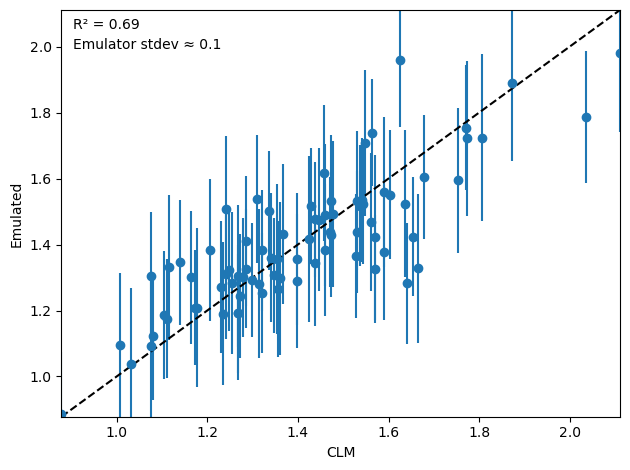

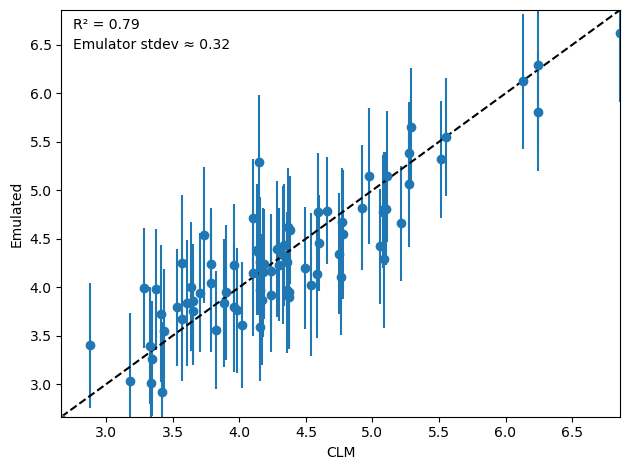

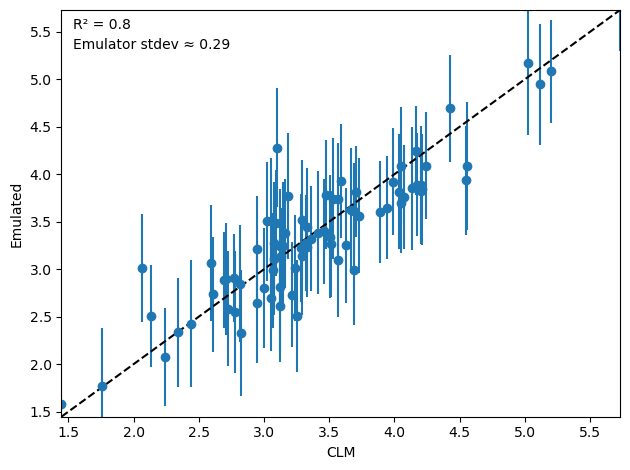

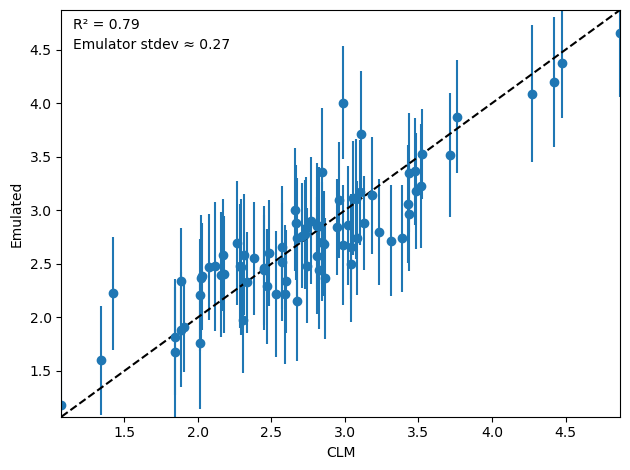

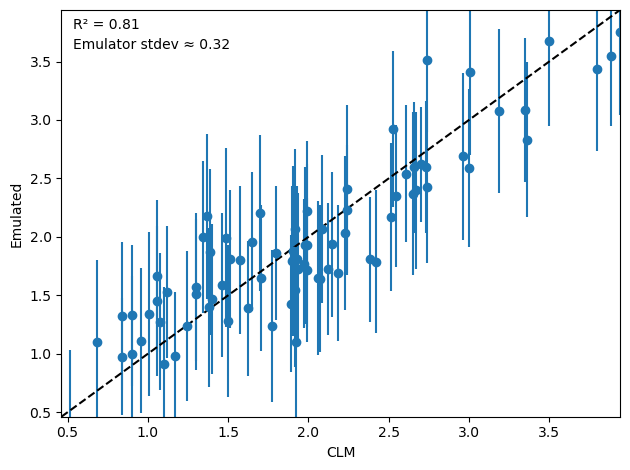

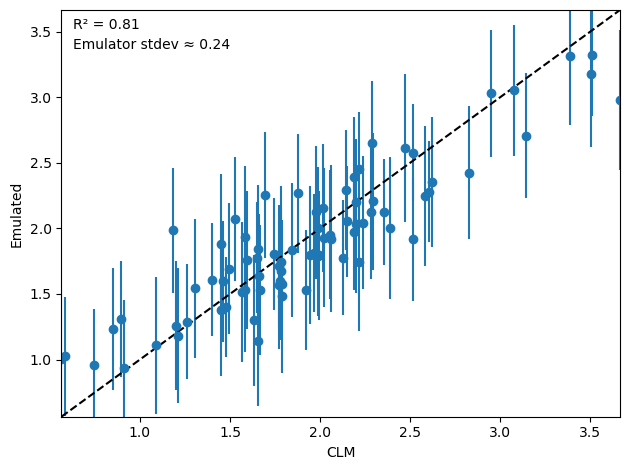

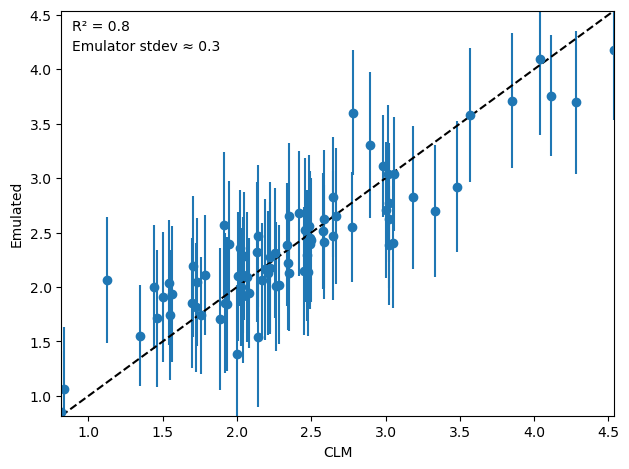

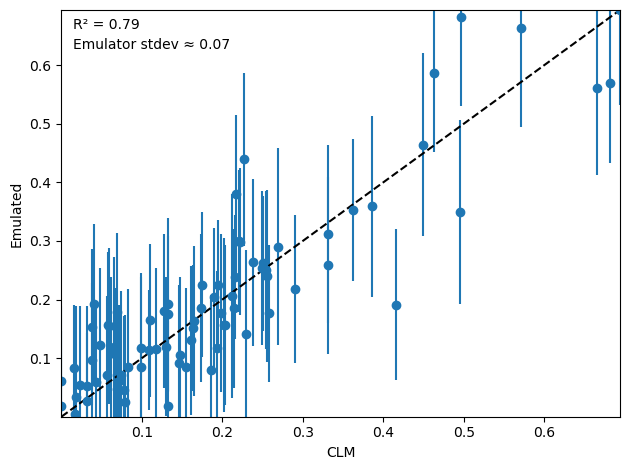

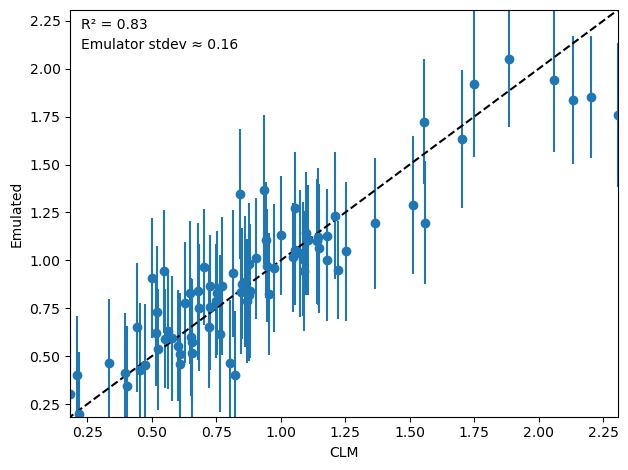

In [48]:
# Train GPP emulators # (2001,2017)
start_year = '2001'
end_year = '2017'

y_data = (60*60*24*ds_Y.GPP_biome_amean).sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './wave4_emulators/biome_gpp_'
validation_fig_dir = './figs/emulator_validation_gpp_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


2026-01-21 13:32:33.544070: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_3/assets


... (17 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_tvc_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_13/assets


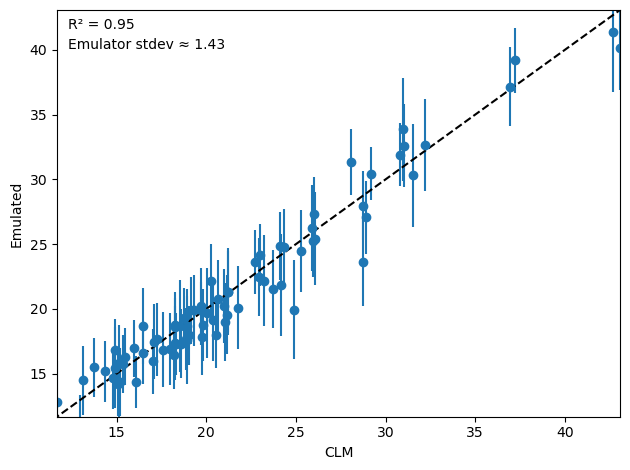

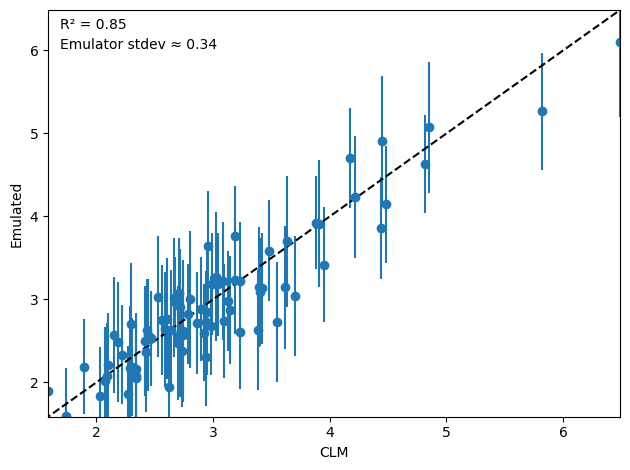

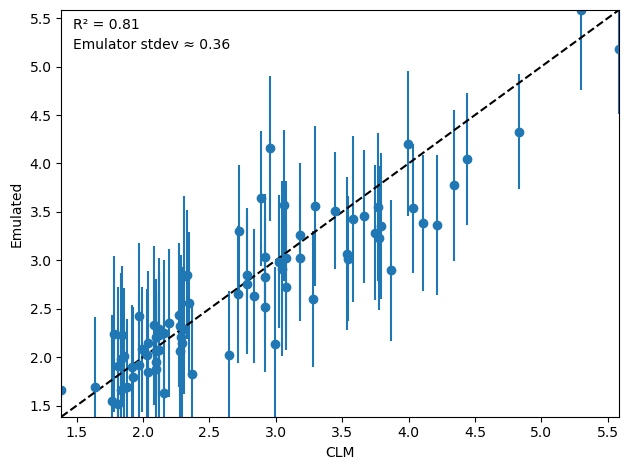

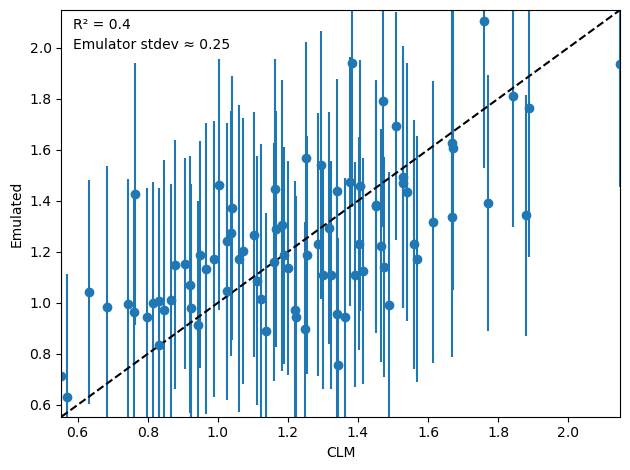

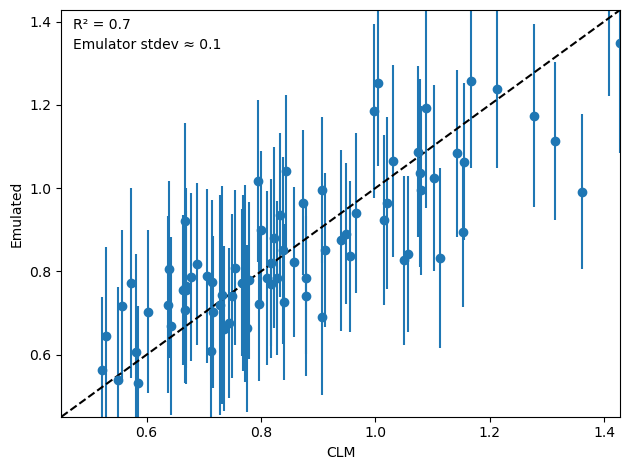

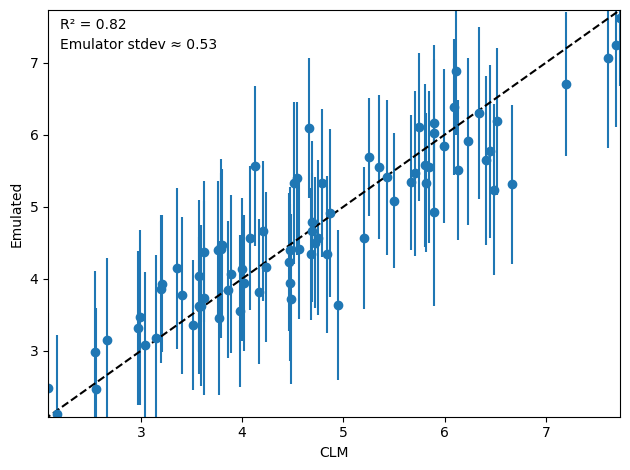

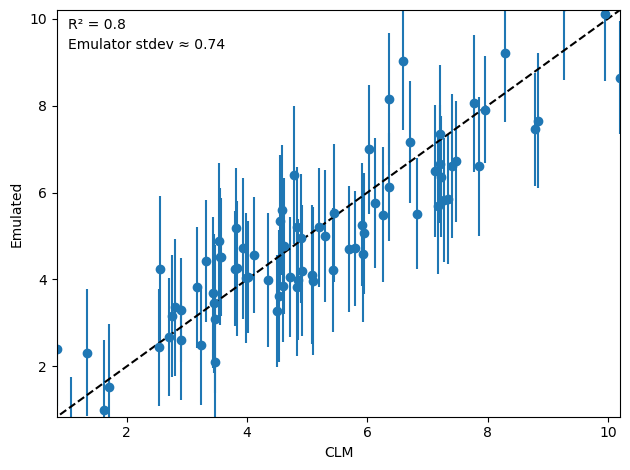

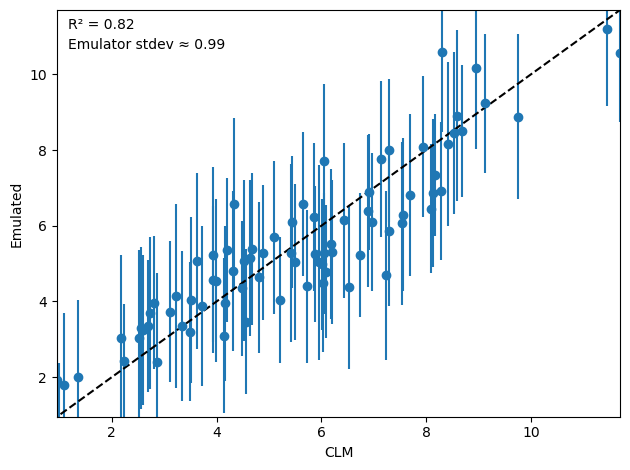

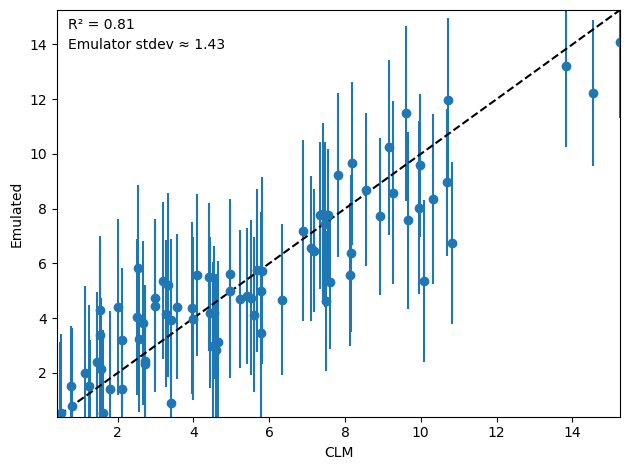

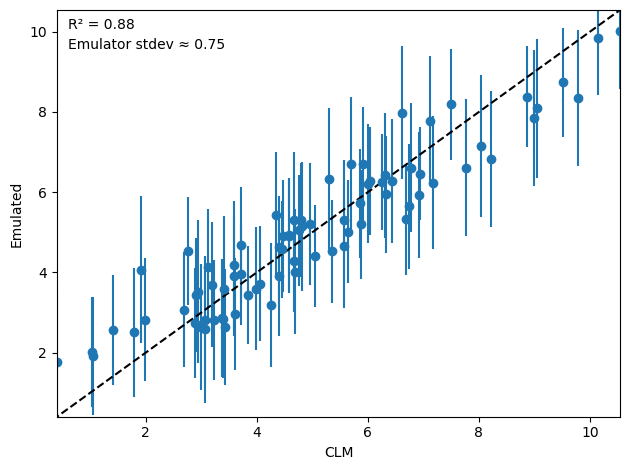

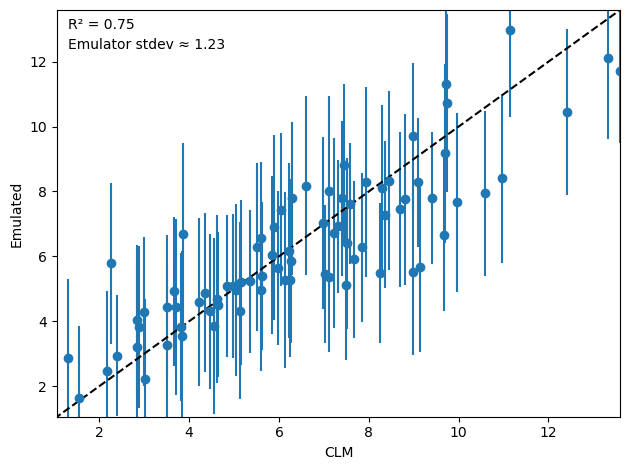

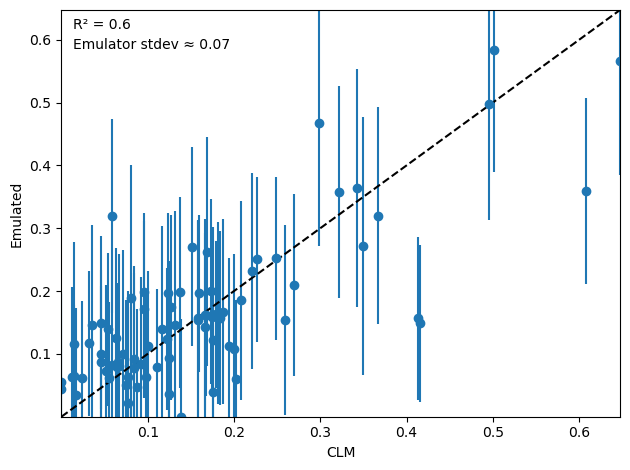

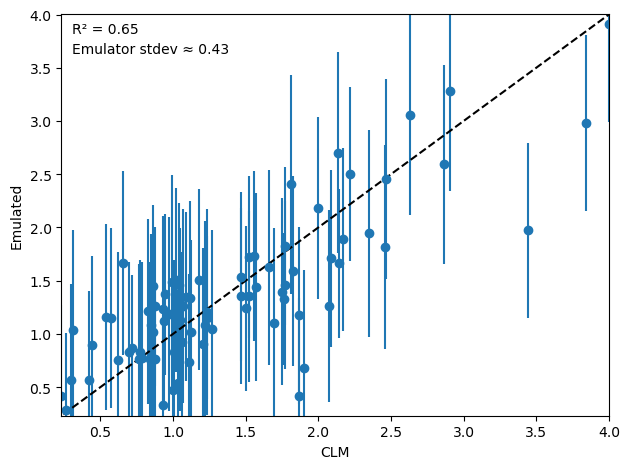

In [10]:
# Train tvc emulators # (2000,2019)
start_year = '2000'
end_year = '2019'
y_data = ((1/1000)*ds_Y.TOTVEGC_biome_amean).sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './wave4_emulators/biome_tvc_'
validation_fig_dir = './figs/emulator_validation_tvc_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)
    
    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


INFO:tensorflow:Assets written to: ./emulators/biome_lh_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_lh_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_13/assets


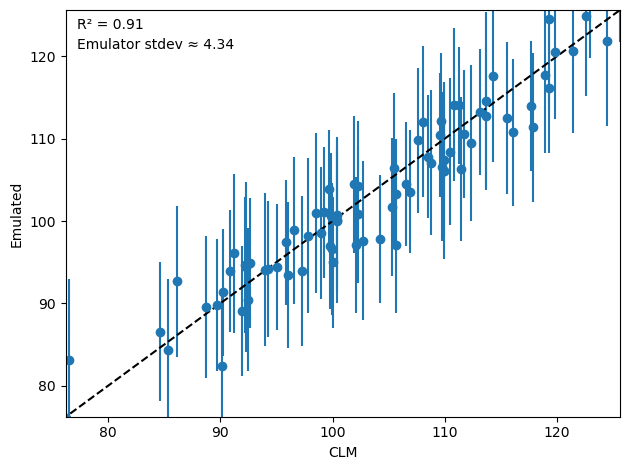

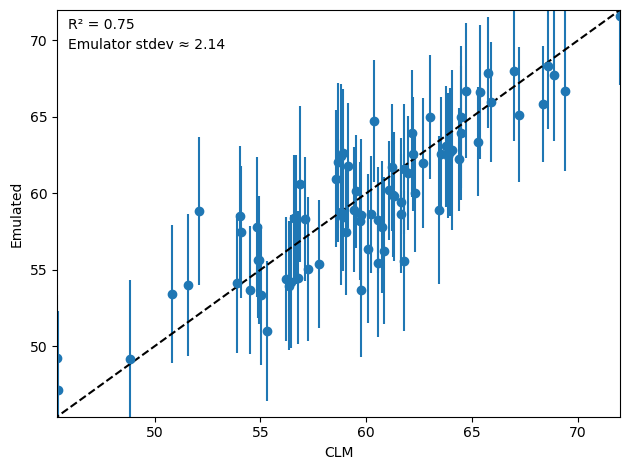

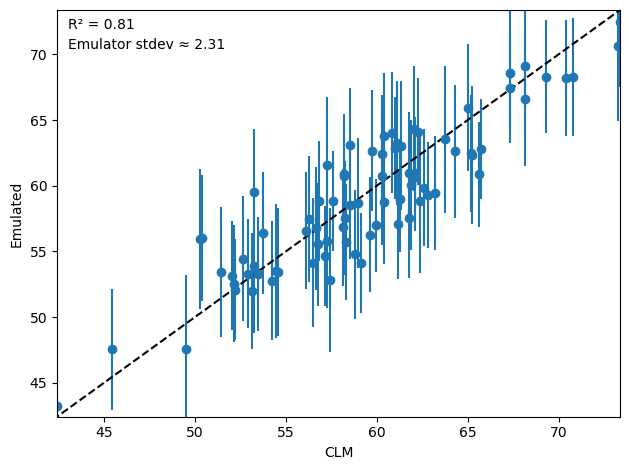

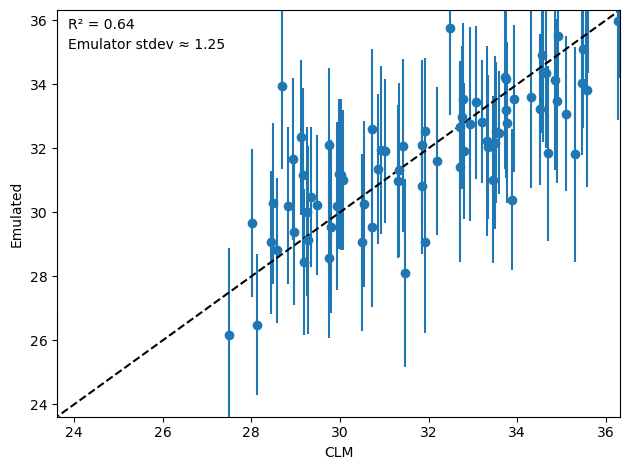

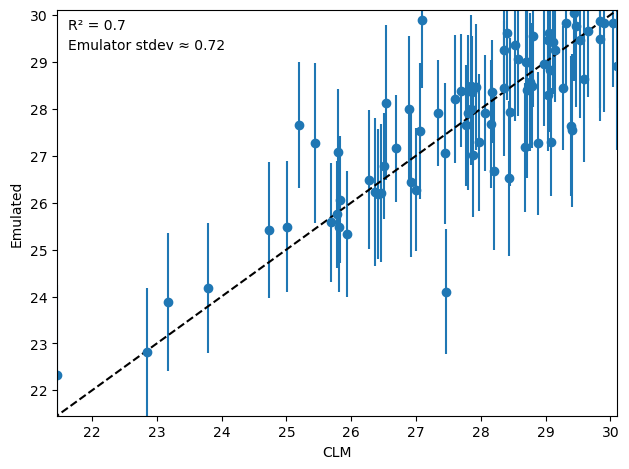

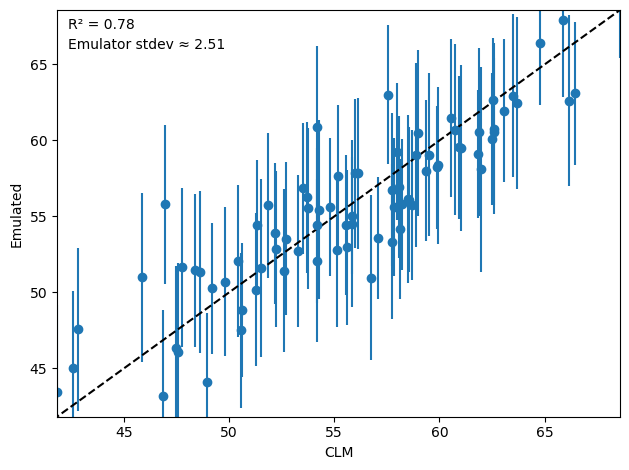

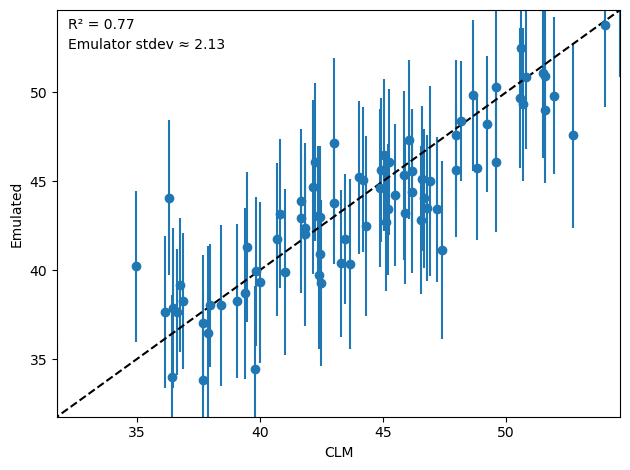

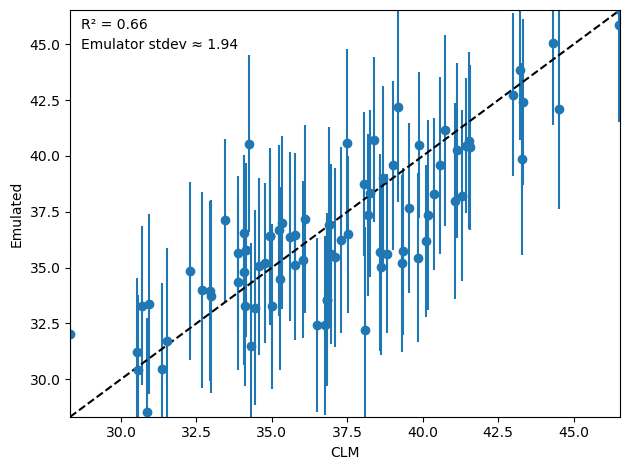

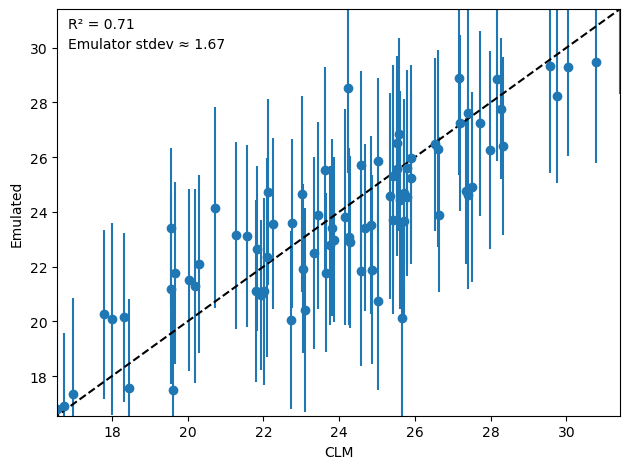

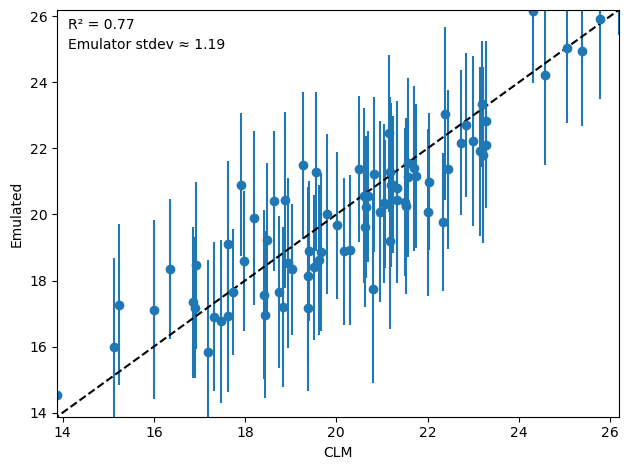

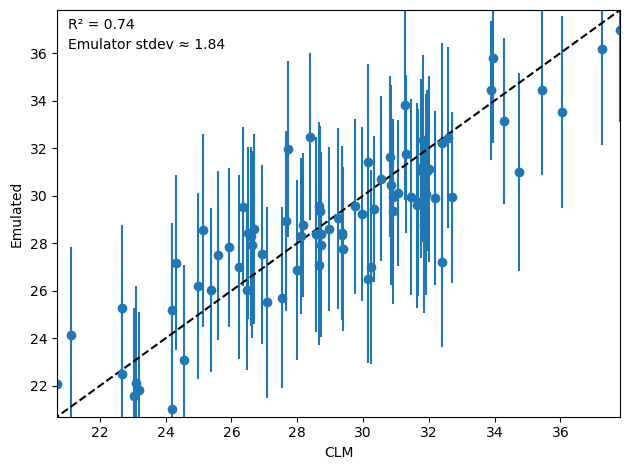

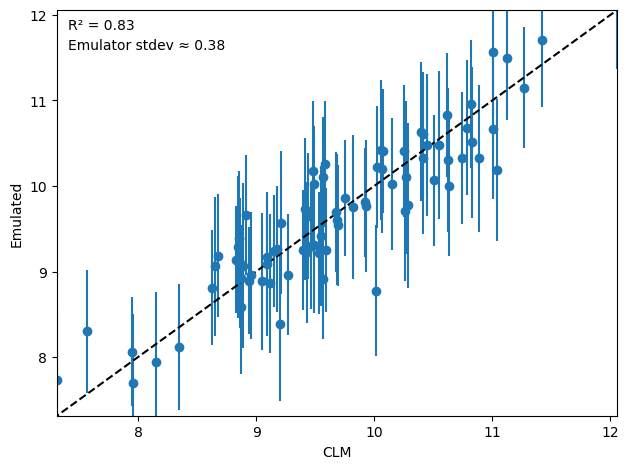

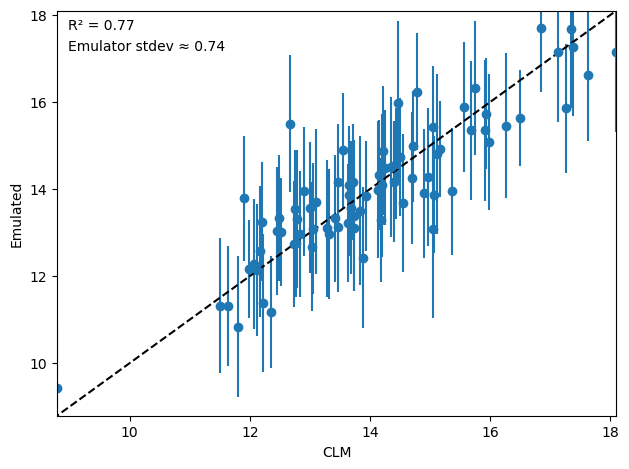

In [50]:
# Train ET emulators
start_year = '2000'
end_year = '2014'
y_data = ds_Y.EFLX_LH_TOT_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './wave4_emulators/biome_lh_'
validation_fig_dir = './figs/emulator_validation_lh_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)
